In [3]:
import pandas as pd
import sidetable
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

In [4]:
activity = pd.read_csv('/home/Escritorio/Bellabeat_Proyect/dailyActivity_merged.csv')
intensities = pd.read_csv('/home/Escritorio/Bellabeat_Proyect/intensities.csv')
calories = pd.read_csv('/home/Escritorio/Bellabeat_Proyect/calories.csv')
sleep = pd.read_csv('/home/Escritorio/Bellabeat_Proyect/sleep.csv')
stress = pd.read_csv('/home/Escritorio/Bellabeat_Proyect/stress.csv')

El promedio de horas de sedentarismo entre los clientes son de 5 hs.
<br>
En algunos casos las horas de sedentarismo son altas, entre 17 a 24 hr.
<br>
Según la OMS en adultos al menos se debería implementar entre 75 a 300 minutos de ejercicios.
<br>
El promedio de actividad alta son de casi 1 hora y su máximo es de 3 hrs y media.

In [6]:
activity.describe()

,Id,TotalSteps,TotalDistance,TrackerDistance,LoggedActivitiesDistance,VeryActiveDistance,ModeratelyActiveDistance,LightActiveDistance,SedentaryActiveDistance,VeryActiveMinutes,FairlyActiveMinutes,LightlyActiveMinutes,SedentaryMinutes,Calories
count,9.400000e+02,940.000000,940.000000,940.000000,940.000000,940.000000,940.000000,940.000000,940.000000,940.000000,940.000000,940.000000,940.000000,940.000000
mean,4.855407e+09,7637.910638,5.489702,5.475351,0.108171,1.502681,0.567543,3.340819,0.001606,21.164894,13.564894,192.812766,991.210638,2303.609574
std,2.424805e+09,5087.150742,3.924606,3.907276,0.619897,2.658941,0.883580,2.040655,0.007346,32.844803,19.987404,109.174700,301.267437,718.166862
min,1.503960e+09,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.320127e+09,3789.750000,2.620000,2.620000,0.000000,0.000000,0.000000,1.945000,0.000000,0.000000,0.000000,127.000000,729.750000,1828.500000
50%,4.445115e+09,7405.500000,5.245000,5.245000,0.000000,0.210000,0.240000,3.365000,0.000000,4.000000,6.000000,199.000000,1057.500000,2134.000000
75%,6.962181e+09,10727.000000,7.712500,7.710000,0.000000,2.052500,0.800000,4.782500,0.000000,32.000000,19.000000,264.000000,1229.500000,2793.250000
max,8.877689e+09,36019.000000,28.030001,28.030001,4.942142,21.920000,6.480000,10.710000,0.110000,210.000000,143.000000,518.000000,1440.000000,4900.000000


Las horas de sueño recomendadas en adultos es entre 7-8 horas, entre los porcentajes el promedio general de sueño son de casi 2 horas.
<br>
Se puede ver que el mínimo de horas es de casi 1 hora, la mediana de 7 horas y el máximo de 13 horas de sueño.

In [7]:
sleep.describe()

,Id,TotalSleepRecords,TotalMinutesAsleep,TotalTimeInBed
count,4.130000e+02,413.000000,413.000000,413.000000
mean,5.000979e+09,1.118644,419.467312,458.639225
std,2.060360e+09,0.345521,118.344679,127.101607
min,1.503960e+09,1.000000,58.000000,61.000000
25%,3.977334e+09,1.000000,361.000000,403.000000
50%,4.702922e+09,1.000000,433.000000,463.000000
75%,6.962181e+09,1.000000,490.000000,526.000000
max,8.792010e+09,3.000000,796.000000,961.000000


In [8]:
activity.stb.freq(['ActivityDate'])
# Son al menos 2 meses de monitoreo

,ActivityDate,count,percent,cumulative_count,cumulative_percent
0,4/15/2016,33,3.510638,33,3.510638
1,4/14/2016,33,3.510638,66,7.021277
2,4/13/2016,33,3.510638,99,10.531915
3,4/12/2016,33,3.510638,132,14.042553
4,4/29/2016,32,3.404255,164,17.446809
5,4/28/2016,32,3.404255,196,20.851064
6,4/27/2016,32,3.404255,228,24.255319
7,4/26/2016,32,3.404255,260,27.659574
8,4/25/2016,32,3.404255,292,31.063830
9,4/24/2016,32,3.404255,324,34.468085


In [9]:
activitydays = activity.stb.freq(['ActivityDate'])

## Activity days

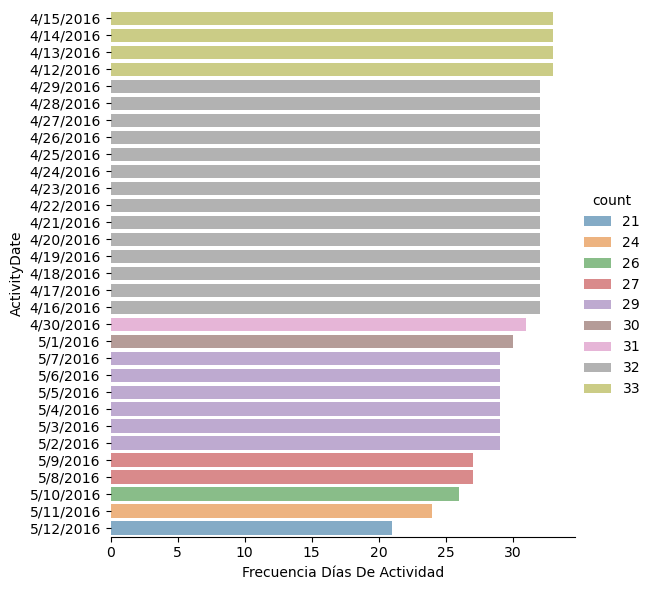

In [10]:
g = sns.catplot(
    data=activitydays, kind="bar",hue="count",
    x="count", y="ActivityDate", 
    palette="tab10", alpha=.6, height=6
)
g.despine(left=True)
g.set_axis_labels("Frecuencia Días De Actividad")

El mes cuatro contiene días de más actividad y con más participantes.
Las estaciones varían en los emisferios, se podría evaluar qué ejercicios o actividades son tendencia para el aire libre y tomar en cuenta ejercicios para interiores en epocas invernales o de lluvia.
Se podría armar rutinas o videos especificos de ejercicios en la aplicación principal para poder incentivar más los días de actividad de los clientes.

## Activity minutes

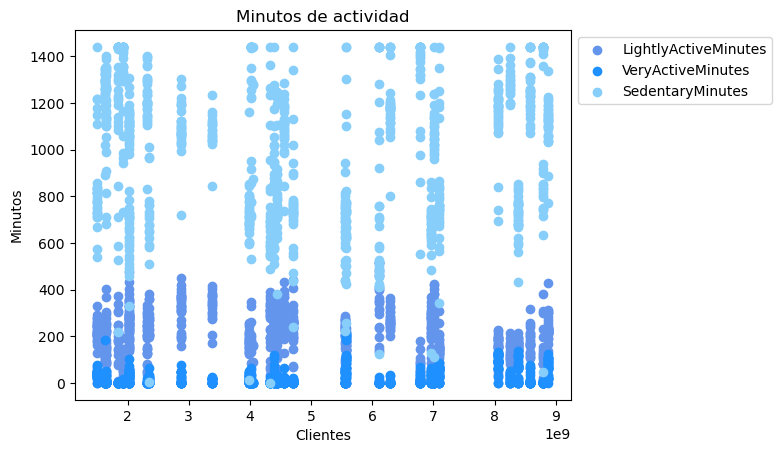

In [11]:
y = np.array(activity["LightlyActiveMinutes"])
y2 = np.array(activity["VeryActiveMinutes"])
y3 = np.array(activity["SedentaryMinutes"])

x = np.array(activity["Id"])

plt.scatter(x,y, color='#6495ED', label='LightlyActiveMinutes')
plt.scatter(x,y2, color='#1E90FF', label='VeryActiveMinutes')
plt.scatter(x,y3, color='#87CEFA', label='SedentaryMinutes')

plt.title("Minutos de actividad")
plt.xlabel("Clientes")
plt.ylabel("Minutos")
plt.legend(loc='upper left', bbox_to_anchor=(1,1))

**Converción de minutos a horas**
<ul>
    <li>1400 -> 23,33 Hrs</li>
    <li>800 -> 13,33 Hrs</li>
    <li>300 -> 5 Hrs</li>
</ul>
<br>
Según la OMS en adultos al menos se debería implementar entre 75 a 300 minutos de ejercicios.
<br>
Mayormente los participantes tienen una actividad moderada de hora y media a 5 hrs, pero las horas de sedentarismo son altas en comparación.

In [50]:
activehours =intensities[intensities['TotalIntensity'] > 0]
activehours.stb.freq(['ActivityHour'])
# Las horas con más actividad de los clientes es de un rango de 11 a 20 HS.

,ActivityHour,count,percent,cumulative_count,cumulative_percent
0,12:00:00,749,5.760652,749,5.760652
1,19:00:00,736,5.660668,1485,11.421320
2,17:00:00,734,5.645285,2219,17.066605
3,18:00:00,733,5.637594,2952,22.704199
4,13:00:00,732,5.629903,3684,28.334102
5,15:00:00,731,5.622212,4415,33.956314
6,16:00:00,730,5.614521,5145,39.570835
7,14:00:00,728,5.599139,5873,45.169974
8,11:00:00,722,5.552992,6595,50.722966
9,20:00:00,706,5.429934,7301,56.152900


## Intensities minutes

<AxesSubplot:xlabel='TotalIntensity', ylabel='Id'>

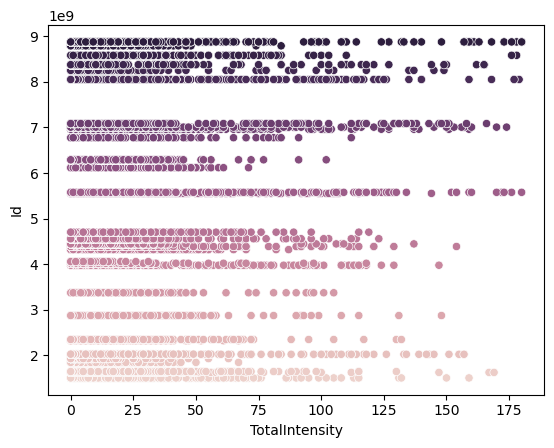

In [14]:
sns.scatterplot(data=intensities, x='TotalIntensity', y='Id', hue="Id", legend=False,)

Poco más de la mitad de los clientes hace ejercicios de alta intensidad.
Lo recomendado es hacer ejercicios de al menos 75 a 300 minutos con intesidad moderada. 

## Calories

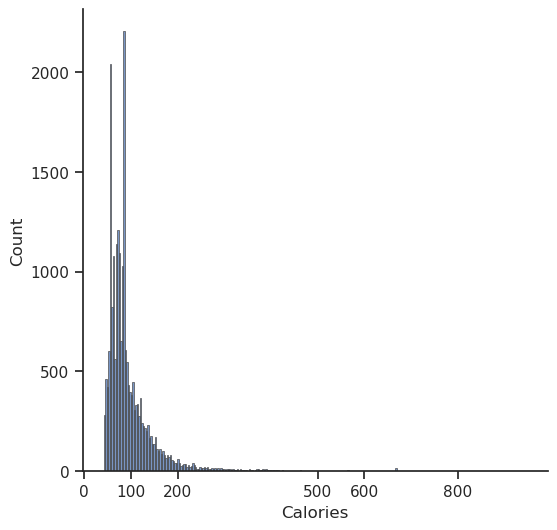

In [15]:
sns.set_theme(style="ticks")
a, ax = plt.subplots(figsize=(6, 6))
sns.despine(a)
sns.histplot(
    calories,
    x="Calories",
    edgecolor=".3",
    linewidth=.5,
    bins='auto',
    legend='auto'
)
ax.set_xticks([0, 100, 200, 500, 600, 800])
# La mayoría de los clientes gastan menos de 200 calorias en el día.

## Stress

([<matplotlib.axis.XTick at 0x7fa9df1d4220>,
 [Text(0, 0, ''), Text(0, 0, ''), Text(0, 0, '')])

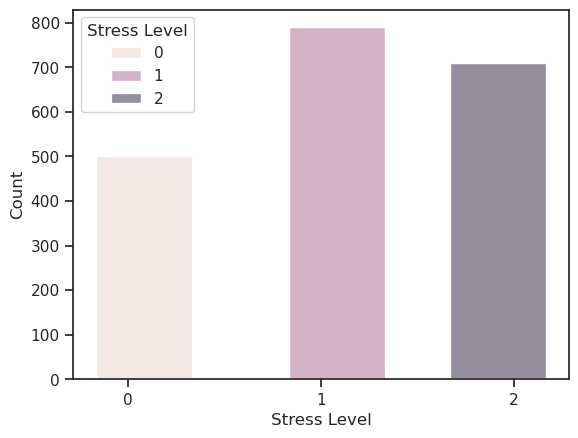

In [45]:
sns.histplot(data=stress, x="Stress Level", hue='Stress Level', shrink=3)
plt.xticks([0, 1, 2])

**Niveles de estrés:**
<ul>
    <li>0- low stress</li>
    <li>1- normal stress</li>
    <li>2- high stress</li>
</ul>
<br>
Los niveles de estrés de los clientes tienden a ser normales a altos, se recomendaría poder registrar las horas de donde los niveles podrían ser altos para poder indicar qué situaciones pueden ser estresantes para el cliente.
<br>
Realizar una serie de meditación o ejercicios de relajación en la aplicación principal sería recomendable.

## Conclusión
En los días sin actividad registrada, es importante verificar si el cliente olvidó el dispositivo. De ser así, se recomienda garantizar el monitoreo a través del móvil.

Las horas de inactividad de los clientes suelen ser elevadas. Para evitar esto, se sugiere crear una alerta que recuerde al cliente la importancia de hacer ejercicio después de cierto tiempo, excluyendo las horas de sueño.
<br>
En cuanto a las horas de sueño de los clientes registrados, se observa que son insuficientes. Según la Clínica Mayo, los adultos deben dormir al menos 7 horas. Por lo tanto, se podría establecer un recordatorio en la aplicación para que el usuario no olvide registrar sus horas de sueño. También se podría crear una alerta en caso de detectar un bajo tiempo de sueño, ya que esto no es saludable y puede representar un riesgo para el cliente.

En relación con las calorías y la intensidad, es fundamental equilibrar la ingesta calórica con el gasto energético. Se recomienda llevar un registro de las calorías consumidas para calcular el excedente diario. Para un adulto, la ingesta diaria de calorías es de aproximadamente 2000, dependiendo de la profesión y el plan calórico del cliente.
Las intensidades de las actividades registradas son altas, lo cual indica que se están realizando actividades impactantes para mejorar la salud. Según la OMS, se recomienda realizar entre 150 y 300 minutos de ejercicio aeróbico de intensidad moderada o entre 72 y 150 minutos de alta intensidad.